# Should we move the first gate? An end-to-end A/B test

**Business question:** Cookie Cats tested moving the first gate from level 30 to level 40. Should the game ship the change?

**Answer:** No. Keep the gate at level 30.

**In plain words:**
- With the gate at level 40, about 4% fewer players come back a week later (at least 3% under a conservative check).
- For every 100,000 new players, that is roughly 800 fewer still playing after a week, and fewer potential buyers.
- The direction of the result does not change under any of the checks, including one for a possible problem in how players were split into groups.

**Key numbers:** 7-day retention fell from 19.0% to 18.2% (-0.8 pp, 95% CI -1.3 to -0.3 pp; p = 0.002, confirmed by bootstrap). The groups are slightly unbalanced; a conservative check for that still finds a significant drop (-0.6 pp).

*Note: this is a retrospective analysis of a public dataset. The design section shows how I would have set up the test before launch.*

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize, proportions_ztest, confint_proportions_2indep

sns.set_theme(style='whitegrid')
df = pd.read_csv('cookie_cats.csv')
df.head()

,userid,version,sum_gamerounds,retention_1,retention_7
0,116,gate_30,3,False,False
1,337,gate_30,38,True,False
2,377,gate_40,165,True,False
3,483,gate_40,1,False,False
4,488,gate_40,179,True,True


## 1. Understand and clean the data
Missing values, duplicated players, group sizes and the distribution of rounds played, then a rule for extreme values.

In [2]:
# Data checks: structure and missing values, duplicated players, group sizes, rounds distribution
df.info()
print('\nDuplicated players:', df.duplicated('userid').sum())
print('\nPlayers per group:\n', df.groupby('version').size())
print('\nRounds played in the first 14 days:\n', df['sum_gamerounds'].describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 90189 entries, 0 to 90188
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   userid          90189 non-null  int64 
 1   version         90189 non-null  object
 2   sum_gamerounds  90189 non-null  int64 
 3   retention_1     90189 non-null  bool  
 4   retention_7     90189 non-null  bool  
dtypes: bool(2), int64(2), object(1)
memory usage: 2.2+ MB

Duplicated players: 0

Players per group:
 version
gate_30    44700
gate_40    45489
dtype: int64

Rounds played in the first 14 days:
 count    90189.000000
mean        51.872457
std        195.050858
min          0.000000
25%          5.000000
50%         16.000000
75%         51.000000
max      49854.000000
Name: sum_gamerounds, dtype: float64


**Cleaning rule.** One player in gate_30 logged 49,854 rounds in their first 14 days (about 150 rounds per hour, non-stop); the next highest is 2,961. This is almost certainly a bot or a logging error, so I drop rows with sum_gamerounds >= 3000 (1 row). I keep players with 0 rounds: they are real users who installed and left, and removing them would bias retention upward.

In [3]:
# Outlier check: players with more than 3,000 rounds
df[df['sum_gamerounds'] > 3000]

,userid,version,sum_gamerounds,retention_1,retention_7
57702,6390605,gate_30,49854,False,True


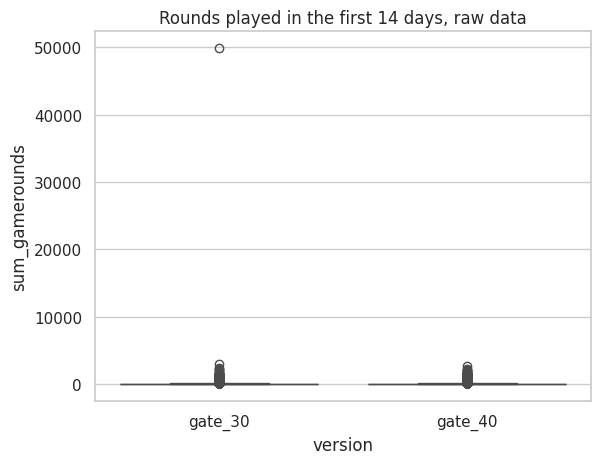

In [4]:
# Raw data: one extreme player flattens the whole chart
sns.boxplot(data=df, x='version', y='sum_gamerounds')
plt.title('Rounds played in the first 14 days, raw data')
plt.show()

In [5]:
# Top 5 values: after the outlier, values decrease gradually (real heavy players)
df['sum_gamerounds'].sort_values(ascending=False).head(5)

,sum_gamerounds
57702,49854
7912,2961
29417,2640
43671,2438
48188,2294


In [6]:
# Apply the cleaning rule and count the rows removed
df_clean = df[df['sum_gamerounds'] < 3000]
print('Rows removed:', len(df) - len(df_clean))

Rows removed: 1


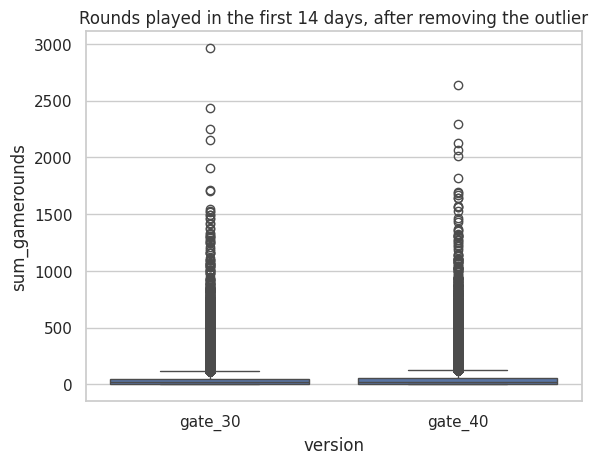

In [7]:
# After removing the outlier: both groups show the same skewed distribution
sns.boxplot(data=df_clean, x='version', y='sum_gamerounds')
plt.title('Rounds played in the first 14 days, after removing the outlier')
plt.show()

## 2. Experiment design (pre-registration)
- **H0:** 7-day retention is the same with the gate at level 30 and at level 40.
- **H1:** 7-day retention is different (two-sided test: the change could help or hurt).
- **Primary metric:** retention_7, because it measures whether players stay, which is what drives long-term revenue. Day-1 retention mostly happens before players reach level 30, so the gate barely affects it.
- **Secondary:** retention_1 · **Guardrail:** sum_gamerounds (engagement should not collapse)
- **alpha = 0.05, power = 0.80, MDE = 1 pp**, because with a baseline of about 19%, losing 1 pp means about 5% fewer retained players, which is a meaningful revenue loss for a freemium game.

In [8]:
# Required sample size per group
baseline = 0.19   # assumed 7-day retention with the current gate (gate_30)
mde = 0.01        # smallest change worth acting on: 1 percentage point
effect = proportion_effectsize(baseline, baseline - mde)
n_needed = NormalIndPower().solve_power(effect_size=effect, alpha=0.05, power=0.8, ratio=1)
print(f'Players needed per group: {n_needed:,.0f}')

# What can we detect with the players we actually have?
n_actual = df_clean.groupby('version').size().min()
h_min = NormalIndPower().solve_power(nobs1=n_actual, alpha=0.05, power=0.8, ratio=1)
mde_actual = baseline - np.sin(np.arcsin(np.sqrt(baseline)) - h_min / 2) ** 2
print(f'Players we have in the smaller group: {n_actual:,}')
print(f'Smallest effect we can reliably detect: {mde_actual * 100:.2f} pp')

Players needed per group: 23,664
Players we have in the smaller group: 44,699
Smallest effect we can reliably detect: 0.73 pp


## 3. Assignment check (sample ratio mismatch)
Were players split 50/50 as designed? A large imbalance would mean the groups may not be comparable.

In [9]:
# Sample ratio mismatch (SRM): were players split 50/50 as designed?
observed = df.groupby('version').size()
expected = [observed.sum() / 2] * 2
chi2, p_srm = stats.chisquare(observed, f_exp=expected)
print(observed)
print(f'Share in gate_40: {observed.iloc[1] / observed.sum():.2%}')
print(f'Chi-square: {chi2:.2f}   p-value: {p_srm:.4f}')

version
gate_30    44700
gate_40    45489
dtype: int64
Share in gate_40: 50.44%
Chi-square: 6.90   p-value: 0.0086


## 4. Results
Retention by group, two-proportion z-test and confidence interval of the difference, plus a SQL cross-check of the same metrics.

In [10]:
# Retention by group, in % (clean data)
g = df_clean.groupby('version')
print((g[['retention_1', 'retention_7']].mean() * 100).round(2))

# Primary metric: 7-day retention, gate_40 minus gate_30
s7, n7 = g['retention_7'].sum(), g['retention_7'].count()
z7, p7 = proportions_ztest(s7, n7)
low7, high7 = confint_proportions_2indep(s7.iloc[1], n7.iloc[1], s7.iloc[0], n7.iloc[0])
diff7 = s7.iloc[1] / n7.iloc[1] - s7.iloc[0] / n7.iloc[0]
print(f'\nretention_7: diff = {diff7 * 100:.2f} pp | z = {z7:.2f} | p = {p7:.4f} | 95% CI = [{low7 * 100:.2f}, {high7 * 100:.2f}] pp')

# Secondary metric: 1-day retention
s1, n1 = g['retention_1'].sum(), g['retention_1'].count()
z1, p1 = proportions_ztest(s1, n1)
low1, high1 = confint_proportions_2indep(s1.iloc[1], n1.iloc[1], s1.iloc[0], n1.iloc[0])
diff1 = s1.iloc[1] / n1.iloc[1] - s1.iloc[0] / n1.iloc[0]
print(f'retention_1: diff = {diff1 * 100:.2f} pp | z = {z1:.2f} | p = {p1:.4f} | 95% CI = [{low1 * 100:.2f}, {high1 * 100:.2f}] pp')

         retention_1  retention_7
version                          
gate_30        44.82        19.02
gate_40        44.23        18.20

retention_7: diff = -0.82 pp | z = 3.16 | p = 0.0016 | 95% CI = [-1.33, -0.31] pp
retention_1: diff = -0.59 pp | z = 1.79 | p = 0.0739 | 95% CI = [-1.24, 0.06] pp


In [11]:
# SQL cross-check with DuckDB: the same metrics, computed the way they would be in a data warehouse
import duckdb
query = "SELECT version, COUNT(*) AS players, "
query += "ROUND(100 * AVG(CAST(retention_1 AS INT)), 2) AS retention_1_pct, "
query += "ROUND(100 * AVG(CAST(retention_7 AS INT)), 2) AS retention_7_pct, "
query += "MEDIAN(sum_gamerounds) AS median_rounds "
query += "FROM df_clean GROUP BY version ORDER BY version"
duckdb.sql(query).df()

,version,players,retention_1_pct,retention_7_pct,median_rounds
0,gate_30,44699,44.82,19.02,17.0
1,gate_40,45489,44.23,18.20,16.0


### Bootstrap
Resample each group, compute the retention difference, plot the distribution and estimate P(gate_30 better).

Bootstrap 95% CI of the difference: [-1.31, -0.33] pp
P(gate_30 retains better than gate_40): 99.9%


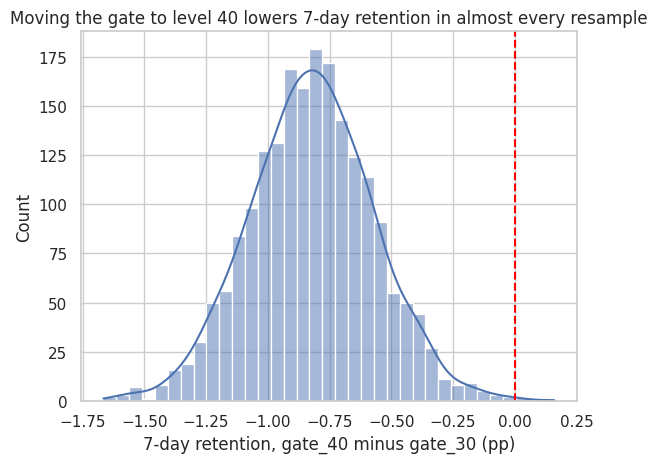

In [12]:
# Bootstrap: resample each group with replacement and recompute the 7-day retention difference
rng = np.random.default_rng(42)
r30 = df_clean.loc[df_clean['version'] == 'gate_30', 'retention_7'].to_numpy()
r40 = df_clean.loc[df_clean['version'] == 'gate_40', 'retention_7'].to_numpy()
B = 2000
diffs = np.array([rng.choice(r40, len(r40)).mean() - rng.choice(r30, len(r30)).mean() for _ in range(B)])

ci_low, ci_high = np.percentile(diffs, [2.5, 97.5])
print(f'Bootstrap 95% CI of the difference: [{ci_low * 100:.2f}, {ci_high * 100:.2f}] pp')
print(f'P(gate_30 retains better than gate_40): {(diffs < 0).mean():.1%}')

sns.histplot(diffs * 100, kde=True)
plt.axvline(0, color='red', linestyle='--')
plt.title('Moving the gate to level 40 lowers 7-day retention in almost every resample')
plt.xlabel('7-day retention, gate_40 minus gate_30 (pp)')
plt.show()

### Guardrail: engagement
Did players in gate_40 play fewer rounds? Rounds are highly skewed, so I compare medians and use a Mann-Whitney U test.

In [13]:
# Guardrail: did engagement (game rounds) drop with the gate at level 40?
print(g['sum_gamerounds'].agg(['mean', 'median']).round(1))
rounds30 = df_clean.loc[df_clean['version'] == 'gate_30', 'sum_gamerounds']
rounds40 = df_clean.loc[df_clean['version'] == 'gate_40', 'sum_gamerounds']
u_stat, p_mw = stats.mannwhitneyu(rounds30, rounds40)
print(f'Mann-Whitney U p-value: {p_mw:.4f}')

         mean  median
version              
gate_30  51.3    17.0
gate_40  51.3    16.0
Mann-Whitney U p-value: 0.0509


### Where does the effect come from? (exploratory)
Split by engagement (30+ rounds vs. fewer), then a sensitivity check on the assignment imbalance.

In [14]:
# Exploratory: is the effect concentrated in players who could have reached the gate?
# Caution: rounds are measured after assignment, so this split is descriptive, not causal.
seg = df_clean.assign(segment=np.where(df_clean['sum_gamerounds'] >= 30, '30+ rounds', 'under 30 rounds'))
table = seg.groupby(['segment', 'version'])['retention_7'].agg(['mean', 'count'])
table['mean'] = (table['mean'] * 100).round(2)
print(table)

hi = seg[seg['segment'] == '30+ rounds'].groupby('version')['retention_7']
z_hi, p_hi = proportions_ztest(hi.sum(), hi.count())
lo = seg[seg['segment'] == 'under 30 rounds'].groupby('version')['retention_7']
z_lo, p_lo = proportions_ztest(lo.sum(), lo.count())
print(f'\n30+ rounds: p = {p_hi:.4f}   |   under 30 rounds: p = {p_lo:.4f}')

                          mean  count
segment         version              
30+ rounds      gate_30  43.87  16655
                gate_40  43.00  16613
under 30 rounds gate_30   4.26  28044
                gate_40   3.93  28876

30+ rounds: p = 0.1093   |   under 30 rounds: p = 0.0490


In [15]:
# Sensitivity: what if gate_40's extra low-engagement players came from an assignment error?
extra = int(n7.iloc[1] - n7.iloc[0])   # players gate_40 has beyond gate_30
low_ret_40 = seg[(seg['segment'] == 'under 30 rounds') & (seg['version'] == 'gate_40')]['retention_7'].mean()
adj_s40 = s7.iloc[1] - extra * low_ret_40
adj_n40 = n7.iloc[1] - extra
z_adj, p_adj = proportions_ztest([s7.iloc[0], adj_s40], [n7.iloc[0], adj_n40])
diff_adj = adj_s40 / adj_n40 - s7.iloc[0] / n7.iloc[0]
print(f'Extra players in gate_40: {extra}')
print(f'Adjusted 7-day retention in gate_40: {adj_s40 / adj_n40:.2%}')
print(f'Adjusted difference: {diff_adj * 100:.2f} pp | p = {p_adj:.4f}')

Extra players in gate_40: 790
Adjusted 7-day retention in gate_40: 18.45%
Adjusted difference: -0.57 pp | p = 0.0301


### Summary chart
The one chart for a non-technical audience: 7-day retention by group, with 95% confidence intervals.

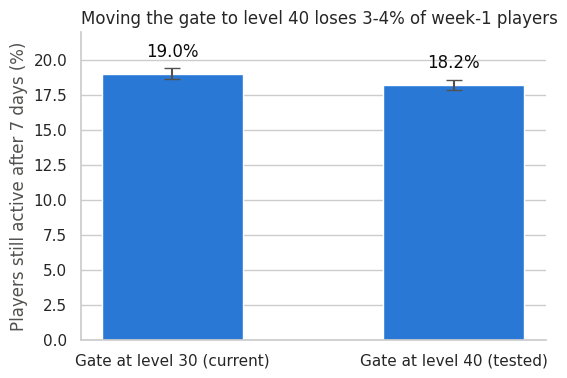

In [16]:
# Board chart: 7-day retention by group, with 95% confidence intervals
rates7 = (s7 / n7 * 100).to_numpy()
err7 = 1.96 * np.sqrt(rates7 * (100 - rates7) / n7.to_numpy())
fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(['Gate at level 30 (current)', 'Gate at level 40 (tested)'], rates7, yerr=err7, capsize=6, width=0.5, color='#2a78d6', ecolor='#52514e')
ax.bar_label(bars, labels=[f'{v:.1f}%' for v in rates7], padding=6, color='#0b0b0b')
ax.set_ylim(0, 22)
ax.set_ylabel('Players still active after 7 days (%)', color='#52514e')
ax.set_title('Moving the gate to level 40 loses 3-4% of week-1 players', loc='left')
ax.grid(axis='x', visible=False)
ax.spines[['top', 'right']].set_visible(False)
plt.show()

## 5. Decision memo
- **Recommendation:** Keep the gate at level 30. Do not ship the move to level 40.
- **Why (key numbers):** 7-day retention fell from 19.02% (gate_30) to 18.20% (gate_40): -0.82 pp, about 4.3% fewer players still active after a week (two-proportion z-test p = 0.0016; 95% CI -1.33 to -0.31 pp). A bootstrap with 2,000 resamples gives the same interval (-1.31 to -0.33 pp), and gate_30 wins in 99.9% of resamples. 1-day retention also dipped (-0.59 pp) but not significantly (p = 0.074), and engagement did not change significantly (51.3 rounds on average in both groups; Mann-Whitney p = 0.051).
- **What the segment split shows (exploratory):** gate_40 retains less both among players with 30+ rounds (-0.87 pp, p = 0.11) and among players with fewer rounds (-0.33 pp, p = 0.049). The 790 extra players in gate_40 sit in the low-engagement segment (under 30 rounds), which suggests the assignment imbalance may push gate_40's retention down. Rounds are counted over 14 days, after assignment and partly after the day-7 check, so this split is descriptive, not causal.
- **Sensitivity:** if those 790 extra players were an assignment error and are removed at the low-engagement retention rate, the drop shrinks to -0.57 pp but stays significant (p = 0.030). This is a robustness check under an assumption, not a corrected estimate (engagement is measured after assignment). The headline estimate remains the measured -0.82 pp; the direction and the recommendation hold.
- **Risks and limits:** the split is 50.4/49.6 (SRM chi-square p = 0.009). It passes the usual SRM threshold (p < 0.001) but is borderline, and the imbalance sits in low-engagement players, so in a real setting I would check the assignment logs before acting. The data only tracks each player's first 14 days and has no spending data, so the effect on revenue is estimated through retention, not measured. Only 7-day retention was the pre-specified decision metric; the other tests are supporting evidence.
- **Next test:** fix or audit the assignment, then try an earlier or softer gate (for example a waiting time instead of a hard block) and track revenue per player alongside 7-day retention.

## 6. How I used AI
I directed the analysis; Claude Code handled the execution. I designed the test and made every analytical decision (the primary metric, the minimum detectable effect, the outlier rule, how to treat the borderline SRM and the final recommendation) and set the checks the results had to pass. Claude Code wrote and ran the code and drafted the text, which I reviewed and edited.

- **Checks:** the notebook re-run from scratch, the key numbers reproduced with two independent methods (SQL vs. pandas, z-test vs. bootstrap) and every variable definition checked against the dataset documentation.
- **What they caught:** the rounds column covers a player's first 14 days, not one week, which changed the outlier reasoning and the caveat on the segment analysis.